# Notebook 4 — Malignancy Models on LNDb
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## The product, in one sentence
> **A second reader that rates how suspicious a lung nodule is — malignancy 1 (highly unlikely)
> to 5 (highly suspicious) — from its position on a CT, fully automatically, and says when it is
> unsure.**

The rating matters because it decides what happens to the patient: nothing, a follow-up CT, or a
PET/biopsy. Radiologists themselves disagree on it (Notebook 1: QWK ≈ 0.53 between two readers),
which makes an objective, reproducible second opinion valuable.

## Constraints we designed for
| Constraint | Consequence in this notebook |
|---|---|
| **Fully automatic** — at test time only the nodule position is known | Every model uses features from *our* segmentation (section 9 measures what that costs) |
| **Ordered, imbalanced target** — few nodules rated 4–5 | The competition's four metrics; class weights / oversampling; models that respect the order |
| **Patients, not nodules** | Nodules of the same CT always stay on the same side of every split |
| **Clinicians must trust it** | Interpretability, robustness per group of nodules, and an explicit *"please check"* signal |
| **Ordinary hardware** | Classic models on a laptop CPU |

## What this notebook contains
| Section | Question |
|---|---|
| 3 | How do we measure success, and what is the bar? |
| 4 | Baselines: "always 2" and a size rule |
| 5 | **Approach A** — classic 5-class classifiers: KNN, SVM, neural network (MLP) |
| 6 | **Approach B** — our approach: predict the radiologists' *average rating*, then the class |
| 7 | Which approach wins? |
| 8 | Where does the model fail — and do radiologists fail there too? |
| 9 | What does full automation cost? |
| 10 | What did the model learn? |
| 11 | Does it work equally well for every kind of nodule? |
| 12 | Knowing when to ask for help |

Only LNDb data is used here. Notebook 6 asks whether adding LIDC-IDRI (Notebook 5) improves the
result and builds the competition file.

**Inputs:** `outputs/features_train.csv`, `outputs/features_train_radiologist.csv` (Notebook 2),
`outputs/working_dataset.csv` (Notebook 1), `outputs/selected_features.json` (Notebook 3)
**Output:** `outputs/lndb_cv_predictions.csv` (out-of-fold predictions, used by Notebook 6)

> ⏱️ Run time: ~20–30 minutes on an 8-core laptop (almost all of it nested cross-validation).

---

## 1. Setup

In [1]:
import json
import shutil
import tempfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (balanced_accuracy_score, cohen_kappa_score, confusion_matrix, f1_score,
                             mean_absolute_error, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

import lndb_utils as U
import lndb_models as M
from lndb_selection import image_type

for w in (UserWarning, RuntimeWarning, FutureWarning, ConvergenceWarning, pd.errors.PerformanceWarning):
    warnings.filterwarnings('ignore', category=w)
plt.rcParams.update(U.PLOT_STYLE)

# ── Settings ──────────────────────────────────────────────────────────────────
N_JOBS       = -1          # CPU cores (-1 = all)
INNER_SPLITS = 3           # inner folds used to tune the classifiers
N_BOOTSTRAP  = 1000        # resamples for confidence intervals
REFER_RATE   = 0.20        # share of nodules handed back to the radiologist (section 12)
LABELS       = U.MAL_LABELS
# ─────────────────────────────────────────────────────────────────────────────
CACHE_DIR = tempfile.mkdtemp(prefix='lndb_nb4_')
memory = Memory(CACHE_DIR, verbose=0)
print('Setup complete.')

Setup complete.


## 2. Load the data
Two feature tables describe the same nodules:
- **Automatic** (`features_train.csv`) — features from our own segmentation, what the final system
  can compute on a new CT. **All models are trained and evaluated on it.**
- **Radiologist masks** (`features_train_radiologist.csv`) — features from the radiologists'
  hand-drawn outlines (nodules ≥ 3 mm only). Used once, in section 9, to measure what automation costs.

The labels come from Notebook 1. The 3 nodules no radiologist rated for malignancy are left out.

In [2]:
labels = pd.read_csv(U.OUTPUT_DIR / 'working_dataset.csv')
keys = ['LNDbID', 'FindingID']
label_cols = ['malignancy_mean', 'malignancy_class', 'malignancy_ratings', 'n_readers', 'readers', 'Volume', 'fold']

def with_labels(features_df):
    """Attach Notebook 1's labels (replacing any older label columns) and drop unrated nodules."""
    out = features_df.drop(columns=[c for c in label_cols if c in features_df.columns]).merge(
        labels[keys + label_cols], on=keys, validate='one_to_one')
    out = out.dropna(subset=['malignancy_mean']).reset_index(drop=True)
    out['malignancy_class'] = out['malignancy_class'].astype(int)
    return out

train = with_labels(pd.read_csv(U.OUTPUT_DIR / 'features_train.csv'))
train_rad = with_labels(pd.read_csv(U.OUTPUT_DIR / 'features_train_radiologist.csv'))
selection = json.loads((U.OUTPUT_DIR / 'selected_features.json').read_text())

features = [c for c in train.columns if c.startswith(('rad_', 'comp_'))]
X      = train[features].values
y      = train['malignancy_class'].values      # 1–5
score  = train['malignancy_mean'].values       # radiologists' average rating
groups = train['LNDbID'].values                # one CT = one patient
FOLDS  = sorted(train['fold'].unique())

print(f'Nodules (automatic features) : {len(train)} from {train.LNDbID.nunique()} CTs')
print(f'Nodules (radiologist masks)  : {len(train_rad)}')
print(f'Features                     : {len(features)}')
print('Classes                      :', {int(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()})
print('Official folds (nodules)     :', {int(k): int(v) for k, v in train.fold.value_counts().sort_index().items()})

Nodules (automatic features) : 765 from 212 CTs
Nodules (radiologist masks)  : 622
Features                     : 1136
Classes                      : {1: 213, 2: 254, 3: 209, 4: 71, 5: 18}
Official folds (nodules)     : {0: 199, 1: 192, 2: 184, 3: 190}


## 3. How we measure success

### 3.1 The competition's metrics
The leaderboard ranks teams by their **average rank over four metrics**, so we report all four:

| Metric | What it rewards |
|---|---|
| **Balanced accuracy** | Getting every class right, rare ones (4, 5) counting as much as common ones |
| **Macro F1** | Same idea, also penalising false alarms in each class |
| **Quadratic weighted kappa (QWK)** | Ordered agreement beyond chance: predicting 4 for a 5 is a small error, 1 for a 5 a big one |
| **Mean absolute error (MAE)** | Average distance on the 1–5 scale — *lower* is better |

### 3.2 Validation protocol — nested cross-validation
```
OUTER loop — the 4 official LNDb folds (CTs split by the dataset authors)
│   train on 3 folds ────────────────────────────┐
│     INNER loop — grouped CV on those 3 folds    │  chooses hyper-parameters, the number of
│     (CTs never split)                           │  features and the cut-offs — training data only
│   predict the 4th fold, never seen before  ◄───┘
└── repeat for every fold → one honest prediction for every nodule ("out-of-fold")
```
Every number in this notebook comes from those out-of-fold predictions; every approach uses the same
folds, so approaches can be compared **fold by fold**. With few nodules rated 5, a single number can
be lucky: we add a **95% confidence interval** of QWK by resampling CTs (bootstrap, 1000×).

In [3]:
def competition_metrics(y_true, y_pred) -> dict:
    return {'Balanced acc.': balanced_accuracy_score(y_true, y_pred),
            'Macro F1': f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
            'QWK': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
            'MAE': mean_absolute_error(y_true, y_pred)}

METRICS = ['Balanced acc.', 'Macro F1', 'QWK', 'MAE']


def bootstrap_ci(y_true, y_pred, patients, n=N_BOOTSTRAP, seed=U.RANDOM_STATE):
    """95% confidence interval of QWK, resampling CTs (not nodules)."""
    rng = np.random.default_rng(seed)
    ids = np.unique(patients)
    rows = {p: np.flatnonzero(patients == p) for p in ids}
    stats = [cohen_kappa_score(y_true[i], y_pred[i], weights='quadratic')
             for i in (np.concatenate([rows[p] for p in rng.choice(ids, len(ids))]) for _ in range(n))]
    return np.percentile(stats, [2.5, 97.5])


def evaluate(pred, y_true=y, data=train) -> dict:
    out = competition_metrics(y_true, pred)
    lo, hi = bootstrap_ci(y_true, pred, data['LNDbID'].values)
    out['QWK 95% CI'] = f'{lo:.2f} – {hi:.2f}'
    out['_ci'] = (lo, hi)
    out['_folds'] = np.array([cohen_kappa_score(y_true[data.fold.values == f], pred[data.fold.values == f],
                                                weights='quadratic') for f in FOLDS])
    return out


def outer_cv(fit, Xm=X, data=train):
    """Out-of-fold predictions over the official folds; fit(X_train, data_train) → model with .predict()."""
    pred, models = np.zeros(len(data), dtype=int), {}
    for f in FOLDS:
        tr, te = (data['fold'] != f).values, (data['fold'] == f).values
        models[f] = fit(Xm[tr], data[tr])
        pred[te] = models[f].predict(Xm[te])
    return pred, models


def inner_cv(data):
    return list(StratifiedGroupKFold(INNER_SPLITS, shuffle=True, random_state=U.RANDOM_STATE)
                .split(np.zeros(len(data)), data['malignancy_class'], data['LNDbID']))


def table_of(names):
    t = pd.DataFrame({k: {m: v for m, v in results[k].items() if not m.startswith('_')} for k in names}).T
    return t


results, oof = {}, {}

### 3.3 The bar: radiologists rating the same nodules
Recomputed on exactly the nodules we model: every pair of radiologists who rated the same nodule.

In [4]:
def reader_pairs(ratings):
    pairs = []
    for s in ratings.astype(str):
        r = [int(v) for v in s.split(',') if v and v != 'nan']
        pairs += [(r[i], r[j]) for i in range(len(r)) for j in range(i + 1, len(r))]
    return np.array(pairs)

pairs = reader_pairs(train.malignancy_ratings)
HUMAN = competition_metrics(pairs[:, 0], pairs[:, 1])
print(f'Radiologist vs radiologist ({len(pairs)} pairs, {(train.n_readers >= 2).sum()} nodules with 2+ readers):')
print('  ' + '   '.join(f'{k} {v:.3f}' for k, v in HUMAN.items()))

Radiologist vs radiologist (309 pairs, 221 nodules with 2+ readers):
  Balanced acc. 0.445   Macro F1 0.411   QWK 0.527   MAE 0.790


This is one reader against another. Our models are compared with the **average** of the readers,
which is less noisy — so a model can score higher against it than one reader against another. The
fairest model-vs-human comparison (the model against each individual reader) is in section 8.2.

## 4. Baselines
A model is only useful if it beats something simple:
1. **Always 2** — the most common class.
2. **Size rule** — size is the strongest single cue radiologists use (Notebook 1). One feature, the
   segmented volume, cut so that each class is predicted as often as in the training folds.

In [5]:
class SizeRule(BaseEstimator, ClassifierMixin):
    """Malignancy from the segmented volume alone; cut-offs reproduce the training class proportions."""
    def fit(self, X, y):
        self.median_ = np.nanmedian(X[:, features.index('comp_volume_log')])
        self.thresholds_ = M.prevalence_thresholds(self._volume(X), np.asarray(y) - 1, n_classes=5)
        return self
    def predict(self, X):
        return M.score_to_class(self._volume(X), self.thresholds_, half_up=True) + 1
    def _volume(self, X):
        return np.nan_to_num(X[:, features.index('comp_volume_log')], nan=self.median_)


oof['Always 2'], _ = outer_cv(lambda Xt, dt: DummyClassifier(strategy='constant', constant=2).fit(Xt, dt.malignancy_class))
oof['Size rule'], _ = outer_cv(lambda Xt, dt: SizeRule().fit(Xt, dt.malignancy_class.values))
for name in ['Always 2', 'Size rule']:
    results[name] = evaluate(oof[name])
table_of(['Always 2', 'Size rule']).style.format({m: '{:.3f}' for m in METRICS})

,Balanced acc.,Macro F1,QWK,MAE,QWK 95% CI
Always 2,0.200,0.100,0.000,0.808,0.00 – 0.00
Size rule,0.317,0.315,0.316,0.894,0.23 – 0.39


## 5. Approach A — classic 5-class classifiers

| Model | Idea | Weak spot here |
|---|---|---|
| **KNN** | A nodule gets the class of its *k* most similar nodules | Distances over many features lose meaning; rare classes rarely win a vote |
| **SVM** (RBF kernel) | The boundary with the widest margin between classes, possibly curved | Needs scaled features |
| **MLP** (neural network) | Layers of neurons learn combinations of features | Many parameters for few examples → strong regularisation (`alpha`) |

One pipeline per model:
```
impute → select (relevance + redundancy) → keep first k → quantile → standardise → [SMOTE] → model
```
- **The number of features is a tuned hyper-parameter** (Notebook 3's candidates: 5 … 100 and all 1136).
- **Class imbalance:** the SVM weights errors on rare classes more (`class_weight='balanced'`); KNN and
  MLP cannot, so **SMOTE** creates synthetic rare-class examples — inside the pipeline, from training
  nodules only.
- The quantile transform removes the heavy skew of the features (Notebook 3); the imputer fills
  features that failed on a test CT.
- Hyper-parameters are chosen by the inner loop to maximise **QWK**.

In [6]:
chosen = []
for name in ['KNN', 'SVM', 'MLP']:
    pipe, grid = M.make_classifier(name, selection=selection, memory=memory)

    def fit(Xt, dt, pipe=pipe, grid=grid):
        return GridSearchCV(pipe, grid, scoring=M.QWK_SCORER, cv=inner_cv(dt), n_jobs=N_JOBS).fit(
            Xt, dt['malignancy_class'].values)

    oof[name], searches = outer_cv(fit)
    results[name] = evaluate(oof[name])
    chosen += [{'model': name, 'test fold': f, **M.describe_params(s.best_params_)} for f, s in searches.items()]
pd.DataFrame(chosen).set_index(['model', 'test fold']).fillna('')

n_neighbors n_features     C  gamma alpha hidden_layer_sizes
model test fold                                                             
KNN   0                31.0         10                                      
      1                31.0         10                                      
      2                15.0          5                                      
      3                31.0         10                                      
SVM   0                            100  10.0  0.001                         
      1                            all   1.0  0.001                         
      2                            all   1.0  scale                         
      3                             10  10.0  0.001                         
MLP   0                             20                1.0              (32,)
      1                            all               10.0           (64, 32)
      2                             20               10.0              (32,)
      3                             50               10.0           (64, 32)

**What the grid searches chose.** The inner loop, which never sees the test fold, confirms
Notebook 3: **KNN prefers few features** (5–10, with many neighbours: 15–31), and the MLP mostly
20–50. The SVM varies between 10 features and all 1136 depending on the fold — with strong
regularisation it can use many weak features, but there is no clear winner. The scores are compared
in section 7.

## 6. Approach B — predict the average rating, then the class (our approach)

### 6.1 The idea
A classifier throws information away. A nodule rated 3.5 (one reader said 3, another 4) and one rated
3.0 (both said 3) are just "class 3 or 4" to a classifier — and a classifier does not know that the
classes are **ordered**. So each model learns the **average rating itself** (regression on 1–5), and
only then is the number turned into a class:

```
features ──► KNN regressor ─┐
features ──► SVR           ─┼─► average score ──► four cut-offs ──► malignancy 1 / 2 / 3 / 4 / 5
features ──► MLP regressor ─┘
```

1. **Regression on the average rating** keeps the order and the "almost 4" information.
2. **A committee of the three models** — they make different kinds of errors, so their average is
   steadier: the same principle the dataset uses for its labels (averaging readers).
3. **Cut-offs that respect the class proportions.** A regression hedges towards the middle of the
   scale, so ordinary rounding (2.5 → 3) predicts too many 2s and 3s and almost no 1s or 5s. Using
   **out-of-fold** scores inside the training data only, the cut-offs are placed so that each class is
   predicted **as often as the radiologists assign it** (*prevalence matching*). Rare classes are also
   up-weighted in training.

The whole procedure is one estimator, `TextureScoreCommittee` in `lndb_models.py` (named after its
first use, on texture), so exactly the same code runs inside cross-validation and for a final model.

In [7]:
class MalignancyCommittee(M.TextureScoreCommittee):
    """The score committee, returning malignancy classes 1–5 (the base class counts from 0)."""
    def predict(self, X):
        return super().predict(X) + 1


def committee_fit(Xt, dt):
    return MalignancyCommittee(selection=selection, class_thresholds=U.MAL_THRESHOLDS, half_up=True,
                                   cutoffs='prevalence', n_jobs=N_JOBS, memory=memory).fit(
        Xt, dt['malignancy_mean'].values, dt['LNDbID'].values)


oof['Committee'], committees = outer_cv(committee_fit)
results['Committee'] = evaluate(oof['Committee'])

oof_score = np.zeros(len(train))
member_pred = {m: np.zeros(len(train), dtype=int) for m in ['KNN', 'SVM', 'MLP']}
fold_thresholds = {}
for f, c in committees.items():
    te = (train.fold == f).values
    oof_score[te] = c.predict_score(X[te])
    for m, p in c.predict_members(X[te]).items():
        member_pred[m][te] = p + 1
    fold_thresholds[f] = np.asarray(c.thresholds_)

oof['Committee (rounding)'] = M.score_to_class(oof_score, U.MAL_THRESHOLDS, half_up=True) + 1
results['Committee (rounding)'] = evaluate(oof['Committee (rounding)'])
print(f"Spearman ρ between committee score and radiologists' average: {spearmanr(oof_score, score)[0]:.3f}")
pd.DataFrame([{'test fold': f, **{f'cut {i + 1}|{i + 2}': round(t, 2) for i, t in enumerate(fold_thresholds[f])},
               **{m: ', '.join(f'{k}={v}' for k, v in p.items()) for m, p in c.best_params_.items()}}
              for f, c in committees.items()]).set_index('test fold')

Spearman ρ between committee score and radiologists' average: 0.545


,cut 1|2,cut 2|3,cut 3|4,cut 4|5,KNN,SVM,MLP
test fold,,,,,,,
0,1.88,2.40,3.25,3.84,"n_neighbors=31, n_features=10","C=1, n_features=all","alpha=10.0, n_features=all"
1,1.90,2.43,3.33,4.03,"n_neighbors=15, n_features=20","C=1, n_features=all","alpha=10.0, n_features=all"
2,1.86,2.45,3.21,3.96,"n_neighbors=31, n_features=50","C=1, n_features=all","alpha=10.0, n_features=all"
3,1.94,2.46,3.24,3.85,"n_neighbors=31, n_features=5","C=1, n_features=all","alpha=10.0, n_features=all"


### 6.2 What does each idea contribute?
Every committee member can also be evaluated **alone** on the same out-of-fold nodules:
- **left → middle column** (same algorithm): predicting the ordered score instead of 5 unordered classes;
- **middle column → committee**: averaging the three models;
- **rounding vs prevalence**: the effect of the cut-off rule.

In [8]:
ablation = pd.DataFrame({
    'as 5-class classifier (section 5)': {m: results[m]['QWK'] for m in member_pred},
    'as score model, alone': {m: cohen_kappa_score(y, p, weights='quadratic') for m, p in member_pred.items()},
})
ablation.loc['Committee, rounding'] = [np.nan, results['Committee (rounding)']['QWK']]
ablation.loc['Committee, prevalence cut-offs (ours)'] = [np.nan, results['Committee']['QWK']]
ablation.style.format('{:.3f}', na_rep='—').set_caption('Out-of-fold QWK')

,as 5-class classifier (section 5),"as score model, alone"
KNN,0.459,0.515
SVM,0.487,0.550
MLP,0.477,0.426
"Committee, rounding",—,0.510
"Committee, prevalence cut-offs (ours)",—,0.525


In [9]:
rows = []
for name in ['Committee (rounding)', 'Committee']:
    p = oof[name]
    rows.append({'cut-offs': 'rounding (1.5 / 2.5 / 3.5 / 4.5)' if 'rounding' in name else 'prevalence matching (ours)',
                 **{m: results[name][m] for m in METRICS},
                 **{f'predicted {k}': int((p == k).sum()) for k in LABELS}})
rows.append({'cut-offs': 'radiologists (true classes)', **{f'predicted {k}': int((y == k).sum()) for k in LABELS}})
pd.DataFrame(rows).set_index('cut-offs').style.format({m: '{:.3f}' for m in METRICS}, na_rep='')

,Balanced acc.,Macro F1,QWK,MAE,predicted 1,predicted 2,predicted 3,predicted 4,predicted 5
cut-offs,,,,,,,,,
rounding (1.5 / 2.5 / 3.5 / 4.5),0.350,0.357,0.510,0.630,101,378,235,51,0
prevalence matching (ours),0.384,0.383,0.525,0.689,217,242,212,80,14
radiologists (true classes),,,,,213,254,209,71,18


**Reading it.**
- **Predicting the ordered score helps KNN and the SVM** (QWK 0.46 → 0.52 and 0.49 → 0.55 as score
  models): as a regressor, the neighbours' *average* rating is informative even when no neighbour has
  the right class. The MLP does not gain.
- **Averaging the three** beats the MLP and KNN alone, but here the **SVR alone is slightly better**
  on QWK (0.55 vs 0.53, out-of-fold): the weaker members pull the average down. We keep the
  committee as the main model because averaging is more stable across datasets (Notebook 6 adds
  LIDC-IDRI), but this is an honest caveat.
- **Prevalence cut-offs vs rounding:** rounding piles the predictions on 2 and 3 (no nodule predicted
  5, for 18 real ones) — good for MAE (0.63 vs 0.69), bad for the rare classes. Prevalence
  matching predicts every class about as often as the radiologists do and gives the better QWK and
  balanced accuracy. Which matters more is a choice of operating point; the competition's mean rank
  decides in Notebook 6.

### 6.3 What the committee's score looks like
Each dot is one nodule, placed at its out-of-fold committee score, one row per true class; the dashed
lines are the cut-offs (averaged over folds).

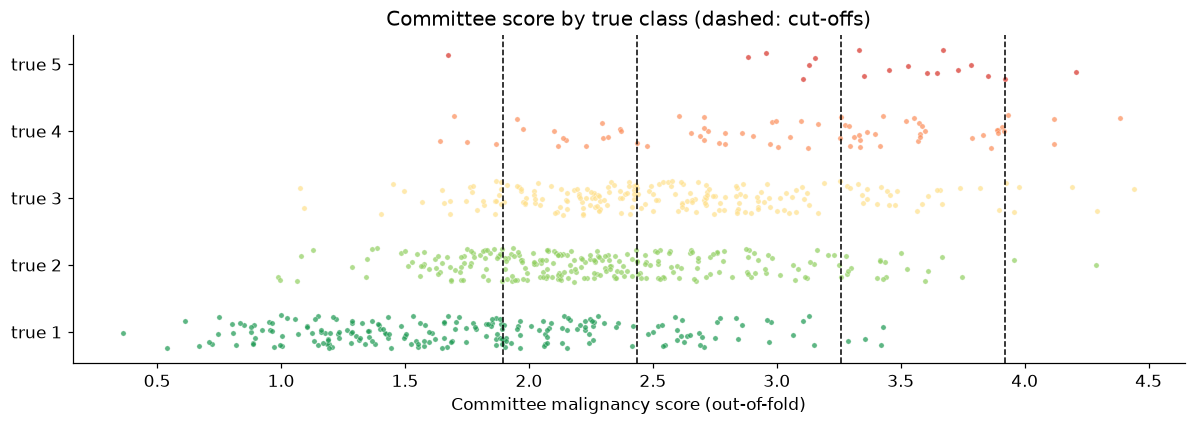

In [10]:
cuts = np.mean(list(fold_thresholds.values()), axis=0)
rng = np.random.default_rng(U.RANDOM_STATE)
fig, ax = plt.subplots(figsize=(11, 4))
for k in LABELS:
    s = oof_score[y == k]
    ax.scatter(s, k + rng.uniform(-0.25, 0.25, len(s)), s=12, alpha=0.7, color=U.MALIGNANCY_COLORS[k - 1],
               edgecolor='white', linewidth=0.3)
for t in cuts:
    ax.axvline(t, color='black', ls='--', lw=1)
ax.set(yticks=LABELS, yticklabels=[f'true {k}' for k in LABELS], xlabel='Committee malignancy score (out-of-fold)',
       title='Committee score by true class (dashed: cut-offs)')
plt.tight_layout(); plt.show()

The score orders the nodules the way the radiologists do (Spearman ρ ≈ 0.55 with their average):
class-1 nodules sit mostly on the left, class-4 and class-5 nodules mostly on the right. But
neighbouring classes overlap heavily — the cut-offs can only be right "on average". This is the same
pattern as the radiologists' own disagreement (Notebook 1: 83% of reader pairs within ±1, 41% exact).

## 7. Which approach wins?

In [11]:
ORDER = ['Always 2', 'Size rule', 'KNN', 'SVM', 'MLP', 'Committee (rounding)', 'Committee']
table = table_of(ORDER)
ranks = pd.concat([table[m].astype(float).rank(ascending=(m == 'MAE')) for m in METRICS], axis=1)
table['mean rank'] = ranks.mean(axis=1)
table.style.format({**{m: '{:.3f}' for m in METRICS}, 'mean rank': '{:.2f}'})

,Balanced acc.,Macro F1,QWK,MAE,QWK 95% CI,mean rank
Always 2,0.200,0.100,0.000,0.808,0.00 – 0.00,6.50
Size rule,0.317,0.315,0.316,0.894,0.23 – 0.39,6.25
KNN,0.422,0.368,0.459,0.847,0.39 – 0.52,4.50
SVM,0.455,0.407,0.487,0.754,0.41 – 0.56,2.00
MLP,0.431,0.388,0.477,0.782,0.41 – 0.55,3.00
Committee (rounding),0.350,0.357,0.510,0.630,0.45 – 0.56,3.25
Committee,0.384,0.383,0.525,0.689,0.46 – 0.59,2.50


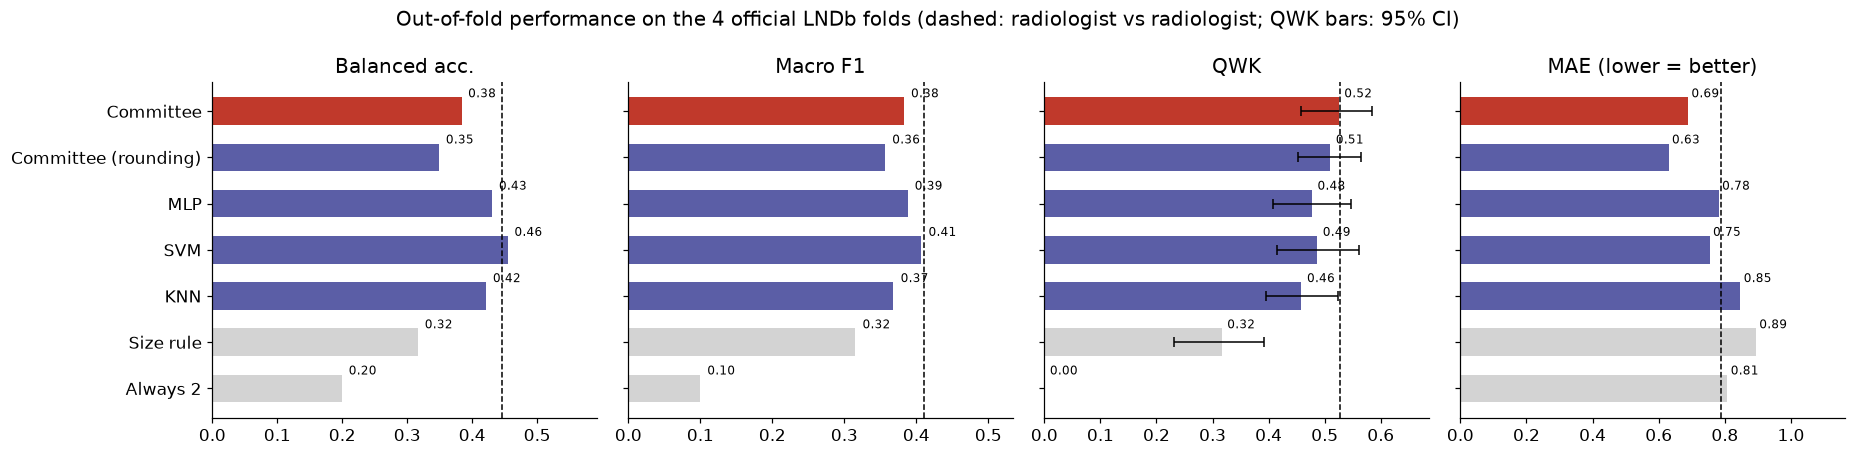

Committee − SVM                    QWK per official fold: [0.028 0.043 0.017 0.062] → better in 4/4 folds
Committee − Size rule              QWK per official fold: [0.181 0.148 0.284 0.209] → better in 4/4 folds
Committee − Committee (rounding)   QWK per official fold: [ 0.039 -0.014  0.022  0.021] → better in 3/4 folds


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
ypos = np.arange(len(ORDER))
for ax, m in zip(axes, METRICS):
    vals = table.loc[ORDER, m].astype(float).values
    colors = [U.COLOR_ACCENT if k == 'Committee' else ('lightgray' if k in ('Always 2', 'Size rule') else U.COLOR_NEUTRAL)
              for k in ORDER]
    ax.barh(ypos, vals, color=colors, height=0.6)
    if m == 'QWK':
        lo = [v - results[k]['_ci'][0] for k, v in zip(ORDER, vals)]
        hi = [results[k]['_ci'][1] - v for k, v in zip(ORDER, vals)]
        ax.errorbar(vals, ypos, xerr=[lo, hi], fmt='none', ecolor='black', lw=1, capsize=3)
    ax.axvline(HUMAN[m], color='black', ls='--', lw=1)
    for yi, v in zip(ypos, vals):
        ax.text(v + 0.01, yi + 0.3, f'{v:.2f}', fontsize=8)
    ax.set(title=m + (' (lower = better)' if m == 'MAE' else ''), xlim=(0, max(vals.max(), HUMAN[m]) * 1.3))
axes[0].set_yticks(ypos, ORDER)
fig.suptitle('Out-of-fold performance on the 4 official LNDb folds (dashed: radiologist vs radiologist; QWK bars: 95% CI)')
plt.tight_layout(); plt.show()

best_clf = max(['KNN', 'SVM', 'MLP'], key=lambda k: results[k]['QWK'])
for other in [best_clf, 'Size rule', 'Committee (rounding)']:
    d = results['Committee']['_folds'] - results[other]['_folds']
    print(f'Committee − {other:<22} QWK per official fold: {np.round(d, 3)} → better in {np.sum(d > 0)}/4 folds')

**Reading the results.**
- **Every learned model clearly beats both baselines.** The size rule alone reaches QWK ≈ 0.32;
  "always 2" is never useful.
- **No approach wins on all four metrics.** The **SVM classifier** is best on balanced accuracy and
  macro F1 (it gets the rare classes right more often); the **committee** is best on QWK (0.53, better
  than the SVM in all 4 folds) and, with rounding, on MAE. By the competition's own rule (mean rank)
  the SVM and the committee are close.
- **All models are at the level of two radiologists** (QWK 0.53 between readers) — but not above it.

> **Caveat on certainty.** The QWK confidence intervals of the learned models overlap widely
> (≈ ±0.06). With ~765 nodules and 18 rated 5, the ranking among the stronger models is suggestive,
> not proven. Notebook 6 asks whether more training data (LIDC-IDRI) moves the whole group up.

## 8. Where does the model fail — and do radiologists fail there too?
### 8.1 Confusion matrix

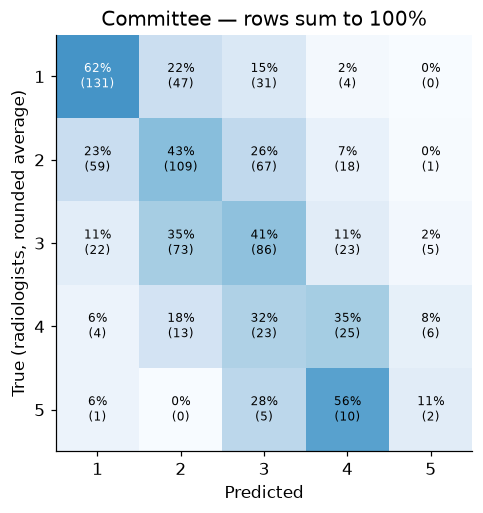

Exact: 46%   within ±1: 86%   2+ classes off: 13.6%


In [13]:
cm = confusion_matrix(y, oof['Committee'], labels=LABELS)
share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{share[i, j]:.0%}\n({cm[i, j]})', ha='center', va='center', fontsize=8,
                color='white' if share[i, j] > 0.6 else 'black')
ax.set_xticks(range(5), LABELS); ax.set_yticks(range(5), LABELS)
ax.set(xlabel='Predicted', ylabel='True (radiologists, rounded average)', title='Committee — rows sum to 100%')
plt.tight_layout(); plt.show()
err = np.abs(oof['Committee'] - y)
print(f'Exact: {np.mean(err == 0):.0%}   within ±1: {np.mean(err <= 1):.0%}   2+ classes off: {np.mean(err >= 2):.1%}')

**Reading the matrix.** Most errors are **one class away**: 86% of the predictions are within ±1 of
the radiologists' class, and 14% are two or more classes off. Class 1 is recognised best; classes 2
and 3 are mostly confused with each other; the few nodules rated 4–5 are often predicted one class
lower — the rare suspicious nodules are the weak point.

### 8.2 The model as one more radiologist
The fairest comparison: on nodules read by two or more radiologists, compare the model's class with
**each individual reader's** rating, exactly as we compared readers with each other.

In [14]:
multi = train.n_readers.values >= 2
mr = np.array([(int(r), p) for ratings, p, keep in zip(train.malignancy_ratings.astype(str), oof['Committee'], multi)
               if keep for r in ratings.split(',') if r and r != 'nan'])
pairs_multi = reader_pairs(train.malignancy_ratings[multi])
human_vs = pd.DataFrame({'model vs radiologist': competition_metrics(mr[:, 0], mr[:, 1]),
                         'radiologist vs radiologist': competition_metrics(pairs_multi[:, 0], pairs_multi[:, 1])}).T
human_vs['pairs compared'] = [len(mr), len(pairs_multi)]
human_vs.style.format({**{m: '{:.3f}' for m in METRICS}, 'pairs compared': '{:.0f}'})

,Balanced acc.,Macro F1,QWK,MAE,pairs compared
model vs radiologist,0.418,0.419,0.499,0.739,486
radiologist vs radiologist,0.445,0.411,0.527,0.790,309


Against **individual** radiologists, the model is close to the agreement between two radiologists —
slightly below on QWK (0.50 vs 0.53), slightly better on mean absolute difference (0.74 vs 0.79). On this comparison it
behaves **like one more human reader**, not like a better one.

### 8.3 Is the model wrong where radiologists disagree?
For nodules read by 2+ radiologists: those where all readers gave the **same rating**, and those where
they **disagreed**. If the model's errors concentrate in the second group, they reflect real
ambiguity in the image rather than a failure of the model.

In [15]:
sub = train.loc[multi, ['malignancy_ratings', 'malignancy_class']].copy()
sub['model'] = oof['Committee'][multi]
sub['readers_agree'] = sub.malignancy_ratings.astype(str).map(lambda s: len(set(s.split(','))) == 1)
summary = sub.groupby('readers_agree').apply(lambda g: pd.Series({
    'nodules': len(g), 'model exact': (g.model == g.malignancy_class).mean(),
    'model MAE': np.abs(g.model - g.malignancy_class).mean()}))
summary.index = summary.index.map({True: 'radiologists agreed', False: 'radiologists disagreed'})
summary.style.format({'nodules': '{:.0f}', 'model exact': '{:.0%}', 'model MAE': '{:.2f}'})

,nodules,model exact,model MAE
readers_agree,,,
radiologists disagreed,134,38%,0.81
radiologists agreed,87,66%,0.43


When the radiologists agreed on the rating, the model reproduces it exactly in 66% of the nodules;
when they disagreed, only in 38% (MAE 0.81 vs 0.43). The model's hardest nodules are the humans'
hardest nodules — part of its "error" is genuine ambiguity in the image and in the label.

## 9. What does full automation cost?
At test time nobody draws the nodule for us, so every model uses **our automatic segmentation**
(Notebook 2). We train and evaluate the **same committee on the same nodules** (those with a
radiologist mask) twice: with features from the radiologists' masks and with features from our
segmentation. Same folds, same nodules — the only difference is who drew the outline.

In [16]:
paired_auto = train.merge(train_rad[keys], on=keys).sort_values(keys).reset_index(drop=True)
paired_rad = train_rad.merge(paired_auto[keys], on=keys).sort_values(keys).reset_index(drop=True)
assert (paired_auto[keys].values == paired_rad[keys].values).all()
y_paired = paired_auto['malignancy_class'].values

automation = {}
for label, data in [('Radiologist masks', paired_rad), ('Automatic segmentation', paired_auto)]:
    pred, _ = outer_cv(committee_fit, data[features].values, data)
    automation[label] = evaluate(pred, y_paired, data)
auto_table = pd.DataFrame({k: {m: v for m, v in r.items() if not m.startswith('_')} for k, r in automation.items()}).T
d = automation['Radiologist masks']['_folds'] - automation['Automatic segmentation']['_folds']
print(f'Nodules compared: {len(paired_auto)}  |  radiologist masks better in {np.sum(d > 0)}/4 folds (QWK)')
auto_table.style.format({m: '{:.3f}' for m in METRICS})

Nodules compared: 622  |  radiologist masks better in 3/4 folds (QWK)


,Balanced acc.,Macro F1,QWK,MAE,QWK 95% CI
Radiologist masks,0.421,0.415,0.559,0.675,0.49 – 0.63
Automatic segmentation,0.394,0.389,0.511,0.717,0.43 – 0.58


This quantifies the **cost of automation**: with the radiologists' outlines the same committee
reaches QWK ≈ 0.56; with our automatic segmentation ≈ 0.51 — about **0.05 of QWK**, and the
radiologist masks win in 3 of 4 folds. Malignancy depends on the *size and border* of the nodule,
which a wrong outline changes directly.
**Better segmentation is the most promising next step** (e.g. a model trained on the LIDC-IDRI
outlines).

## 10. What did the model learn? (interpretability)
For a model that uses 1136 features, "the importance of feature #734" is meaningless. Instead we ask
**which kind of information** the model relies on: for each group of features we shuffle **all of them
together** across the nodules of the test fold (the group carries no information any more, the model
is unchanged) and measure how much the agreement between the committee's score and the radiologists'
average drops (Spearman ρ). Shuffling a whole group at once avoids correlated features "covering"
for each other. Groups: by **image version** and by **feature family**.

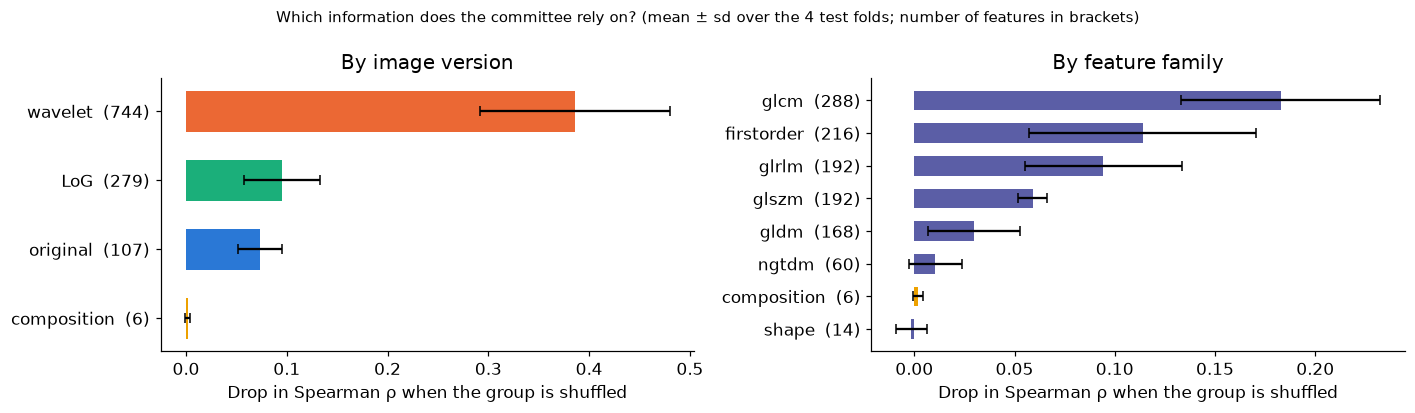

In [17]:
def feature_family(f):
    return 'composition' if f.startswith('comp_') else f.split('_')[2]

GROUPINGS = {'image version': {g: [i for i, f in enumerate(features) if image_type(f) == g]
                               for g in ['original', 'wavelet', 'LoG', 'composition']},
             'feature family': {g: [i for i, f in enumerate(features) if feature_family(f) == g]
                                for g in ['composition', 'firstorder', 'shape', 'glcm', 'glrlm', 'glszm', 'gldm', 'ngtdm']}}
N_SHUFFLES = 3
rng = np.random.default_rng(U.RANDOM_STATE)
importance = []
for f, c in committees.items():
    te = (train.fold == f).values
    Xte, s_true = X[te], score[te]
    base = spearmanr(c.predict_score(Xte), s_true)[0]
    for grouping, groups_ in GROUPINGS.items():
        for g, cols in groups_.items():
            drops = []
            for _ in range(N_SHUFFLES):
                Xp = Xte.copy()
                Xp[:, cols] = Xte[rng.permutation(len(Xte))][:, cols]
                drops.append(base - spearmanr(c.predict_score(Xp), s_true)[0])
            importance.append({'grouping': grouping, 'group': g, 'fold': f, 'drop': np.mean(drops)})
importance = pd.DataFrame(importance)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (grouping, groups_) in zip(axes, GROUPINGS.items()):
    imp = importance[importance.grouping == grouping].groupby('group')['drop'].agg(['mean', 'std']).reindex(groups_).sort_values('mean')
    color = [U.SOURCE_COLORS.get(g, U.COLOR_NEUTRAL) if grouping == 'image version' else
             (U.SOURCE_COLORS['composition'] if g == 'composition' else U.COLOR_NEUTRAL) for g in imp.index]
    ax.barh(imp.index, imp['mean'], xerr=imp['std'], color=color, ecolor='black', capsize=3, height=0.6)
    ax.set_yticks(range(len(imp)), [f'{g}  ({len(groups_[g])})' for g in imp.index])
    ax.set(xlabel='Drop in Spearman ρ when the group is shuffled', title=f'By {grouping}')
fig.suptitle('Which information does the committee rely on? (mean ± sd over the 4 test folds; number of features in brackets)', fontsize=10)
plt.tight_layout(); plt.show()

**How to read it:** a longer bar means the model gets worse when that information is destroyed.
- **The wavelet features carry most of the signal** — shuffling them costs far more than shuffling
  the original-image features. The linear probes of Notebook 3 did not need them, but the
  non-linear models do: they combine fine- and coarse-scale information that the filters isolate.
  This is the justification for extracting ~1000 features.
- **Texture matrices (GLCM) and first-order intensity** matter most among families.
- **Shape and composition look unimportant — because they are replaceable.** Size is also encoded
  in many intensity and texture features (total energy, zone sizes), which take over when the 14
  shape features are shuffled. Importance here means *irreplaceable*, not *useful* (section 10.2).

### 10.2 Does the model follow radiological common sense?
Size is the strongest cue radiologists use (Notebook 1). Plotting the committee's score against the
segmented volume shows how the model relates to it:

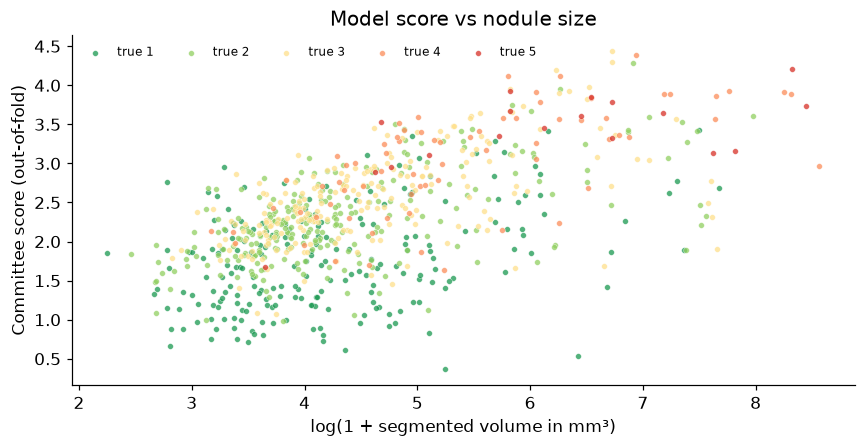

Spearman ρ(volume, committee score) = 0.58   ρ(volume, radiologists) = 0.30


In [18]:
volume = train['comp_volume_log'].values
fig, ax = plt.subplots(figsize=(8, 4.2))
for k in LABELS:
    m = y == k
    ax.scatter(volume[m], oof_score[m], s=14, alpha=0.75, color=U.MALIGNANCY_COLORS[k - 1], edgecolor='white',
               linewidth=0.3, label=f'true {k}')
ax.set(xlabel='log(1 + segmented volume in mm³)', ylabel='Committee score (out-of-fold)',
       title='Model score vs nodule size')
ax.legend(frameon=False, loc='upper left', ncol=5, fontsize=8)
plt.tight_layout(); plt.show()
print(f'Spearman ρ(volume, committee score) = {spearmanr(volume, oof_score, nan_policy="omit")[0]:.2f}   '
      f'ρ(volume, radiologists) = {spearmanr(volume, score, nan_policy="omit")[0]:.2f}')

The model's score rises clearly with nodule size (ρ ≈ 0.58) — more strongly than the radiologists'
average does with the same segmented volume (ρ ≈ 0.3). Size is the most visible, reliable cue in the
images and the model leans on it heavily; the radiologists also weigh border and context the
features capture less well. This is a known risk: a large benign nodule (e.g. a calcified one) may
be over-rated.

## 11. Does it work equally well for every kind of nodule?
**Fairness note.** LNDb's annotation tables contain no demographics (age, sex), so fairness by patient
group cannot be audited — a limitation stated in the ethics document. What we *can* check is
robustness across **types of nodules, labels and acquisition conditions**. QWK is unstable on small
groups, so we report the share of exact predictions, the share within ±1 and the mean absolute error.

In [19]:
acq = pd.read_csv(U.TRAIN_CSV_DIR / 'LNDbAcqParams.csv')[['LNDbID', 'ManufacturerModelName']]
sub = train[['LNDbID', 'is_small', 'seg_status', 'n_readers', 'readers', 'dice_vs_radiologist', 'texture_name']].merge(
    acq, on='LNDbID', how='left')
sub['err'] = np.abs(oof['Committee'] - y)
GROUP_DEFS = {
    'Nodule size': np.where(sub.is_small, '< 3 mm (no radiologist mask)', '≥ 3 mm'),
    'Segmentation quality (Dice)': pd.cut(sub.dice_vs_radiologist, [0, 0.5, 0.75, 1], labels=['< 0.50', '0.50–0.75', '> 0.75'])
                                     .astype(str).replace('nan', 'no mask (< 3 mm)'),
    'Radiologists who rated it': np.where(sub.n_readers >= 2, '2 or more', 'only 1'),
    'Single reader: who': np.where(sub.n_readers == 1, 'radiologist ' + sub.readers.astype(str), None),
    'Texture': sub.texture_name.values,
    'Scanner': sub.ManufacturerModelName.values,
    'True malignancy': y.astype(str),
}
rows = []
for dim, lab in GROUP_DEFS.items():
    for g, part in sub.groupby(pd.Series(lab, index=sub.index)):
        rows.append({'dimension': dim, 'group': g, 'nodules': len(part), 'exact': (part.err == 0).mean(),
                     'within ±1': (part.err <= 1).mean(), 'MAE': part.err.mean()})
pd.DataFrame(rows).set_index(['dimension', 'group']).style.format(
    {'nodules': '{:.0f}', 'exact': '{:.0%}', 'within ±1': '{:.0%}', 'MAE': '{:.2f}'})

**Reading the table.**
- **Nodule size:** nodules < 3 mm are rated as well as larger ones (MAE 0.57 vs 0.72) — they are
  almost all benign and easy.
- **Segmentation quality matters:** when our outline disagrees with the radiologist's (Dice < 0.5),
  the error grows (MAE 0.90 vs 0.68) — the cost of automation of section 9, nodule by nodule.
- **Who read it matters:** among single-reader nodules, the error depends on the radiologist —
  radiologists 3 and 4, who use the scale most differently (Notebook 1 §5.4: radiologist 3 gives "1"
  most often, radiologist 4 the highest ratings), are the hardest to agree with (MAE 0.89 and 0.87);
  radiologist 5 is the easiest (0.53). Part of the "error" is the reader effect.
- **Texture:** GGO nodules are the hardest (MAE 1.00, 37 nodules) — rare and faint.
- **Scanner:** no scanner model is disadvantaged (MAE 0.66–0.70).
- **The largest gap is by true class:** nodules rated 4 and 5 have the largest errors — few examples,
  and the clinically most important ones. This is the main risk of the system.

## 12. Knowing when to ask for help
A second reader is more useful if it says **"I'm not sure about this one"**. The committee gives a
natural confidence measure: **how far the score is from the nearest cut-off**. A nodule scoring right on
a boundary between two classes is the least certain.

Is that confidence *useful*? If the model hands back its least confident nodules to the radiologist,
how many of its **mistakes** go with them? A useless measure would catch errors at the same rate as a
random selection (the diagonal).

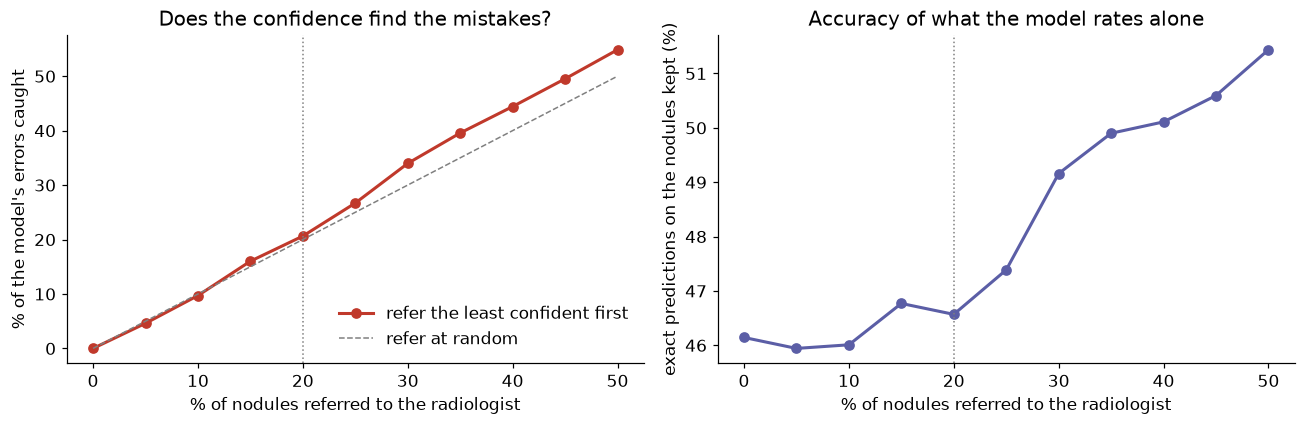

Referring the 20% least confident nodules:
  errors caught               : 21% of all the model's errors (random: 20%)
  exact on the nodules kept   : 47%  (vs 46% on all)


In [20]:
margin = np.array([np.min(np.abs(s - fold_thresholds[f])) for s, f in zip(oof_score, train.fold)])
order = np.argsort(margin)                     # least confident first
wrong = oof['Committee'] != y
big = np.abs(oof['Committee'] - y) >= 2

curve = []
for r in np.arange(0, 0.505, 0.05):
    n_ref = int(round(r * len(order)))
    ref, keep = order[:n_ref], order[n_ref:]
    curve.append({'referred': r, 'errors caught': wrong[ref].sum() / wrong.sum(),
                  'exact on kept': 1 - wrong[keep].mean(), 'MAE on kept': np.abs(oof['Committee'] - y)[keep].mean()})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(curve.referred * 100, curve['errors caught'] * 100, marker='o', color=U.COLOR_ACCENT, lw=2,
             label='refer the least confident first')
axes[0].plot([0, 50], [0, 50], color='gray', ls='--', lw=1, label='refer at random')
axes[0].set(xlabel='% of nodules referred to the radiologist', ylabel="% of the model's errors caught",
            title='Does the confidence find the mistakes?')
axes[0].legend(frameon=False, loc='lower right')
axes[1].plot(curve.referred * 100, curve['exact on kept'] * 100, marker='o', color=U.COLOR_NEUTRAL, lw=2)
axes[1].set(xlabel='% of nodules referred to the radiologist', ylabel='exact predictions on the nodules kept (%)',
            title='Accuracy of what the model rates alone')
for ax in axes:
    ax.axvline(REFER_RATE * 100, color='gray', ls=':', lw=1)
plt.tight_layout(); plt.show()

row = curve.loc[np.isclose(curve.referred, REFER_RATE)].iloc[0]
print(f'Referring the {REFER_RATE:.0%} least confident nodules:')
print(f"  errors caught               : {row['errors caught']:.0%} of all the model's errors (random: {REFER_RATE:.0%})")
print(f"  exact on the nodules kept   : {row['exact on kept']:.0%}  (vs {1 - wrong.mean():.0%} on all)")

**An honest negative result.** For malignancy, the distance to the nearest cut-off is a **poor**
confidence measure: referring 20% of the nodules catches only ~21% of the model's errors — no better
than random. With five narrow classes, almost every nodule is close to *some* cut-off, so the
distance says little. (For texture, with three wide classes, the same idea caught ~64% of the errors
— appendix.) A better "please check" signal for malignancy would need another measure, e.g. how much
the three committee members disagree — left as future work. The product should therefore present the
**score** itself (e.g. 3.4) alongside the class, so the radiologist sees borderline cases.

## 13. Save the out-of-fold predictions
Notebook 6 compares this LNDb-only committee with models that also use LIDC-IDRI, on exactly the same
folds and nodules.

In [21]:
train[keys + ['fold', 'malignancy_class', 'malignancy_mean']].assign(
    committee_score=oof_score.round(4), committee=oof['Committee'], **{k: oof[k] for k in ['KNN', 'SVM', 'MLP', 'Size rule']}
).to_csv(U.OUTPUT_DIR / 'lndb_cv_predictions.csv', index=False)
shutil.rmtree(CACHE_DIR, ignore_errors=True)
print('Saved outputs/lndb_cv_predictions.csv')

Saved outputs/lndb_cv_predictions.csv


## Summary

In [22]:
summary = table.loc[['Always 2', 'Size rule', 'KNN', 'SVM', 'MLP', 'Committee'], METRICS].astype(float)
summary.loc['Radiologist vs radiologist'] = [HUMAN[m] for m in METRICS]
summary.style.format('{:.3f}')

,Balanced acc.,Macro F1,QWK,MAE
Always 2,0.200,0.100,0.000,0.808
Size rule,0.317,0.315,0.316,0.894
KNN,0.422,0.368,0.459,0.847
SVM,0.455,0.407,0.487,0.754
MLP,0.431,0.388,0.477,0.782
Committee,0.384,0.383,0.525,0.689
Radiologist vs radiologist,0.445,0.411,0.527,0.790


### Conclusions
1. **Malignancy can be rated automatically at the level of a second radiologist** (QWK ≈ 0.53 against
   the readers' average; 0.50 against individual readers vs 0.53 between readers), from the nodule's
   position alone.
2. **No single model wins every metric:** the SVM classifier is best on balanced accuracy and macro F1,
   the score committee on QWK and MAE. Predicting the ordered score helped KNN and the SVM.
3. **Errors are mostly one class away** (86% within ±1) and concentrate where radiologists disagree.
4. **Automation costs ≈ 0.05 QWK**: size and border depend on the outline.
5. **The weak spots** are the rare suspicious nodules (4–5), GGO nodules and the reader effect; the
   confidence measure that worked for texture does not work for malignancy.

### Limitations
- ~765 nodules, only 18 rated 5: wide confidence intervals.
- Labels are subjective; most nodules have a single reader.
- One hospital; no demographic data.

**Next → Notebook 5** prepares LIDC-IDRI, and **Notebook 6** tests whether it makes these models better
on LNDb.